# Capse.jl Chains

In this notebook we will show how to use the Capse.jl emulator in combination with Turing.jl, performing a Planck lite analysis. In particular, we are gonna show:

- How to compute the Maximum A Posteriori (MAP), using the L-BFGS method provided by Optim.jl
- How to use Pathfinder.jl to obtain a quick posterior estimate and initialize chains
- How to use NUTS and MicroCanonical Hamiltonian MonteCarlo as sampling algorithms

Let us start activating the Julia environment and loading any relevent packages

In [1]:
using Pkg
Pkg.activate(".")

  Activating project at `~/Desktop/Waterloo/Masters/JulaiLocalEnv`


In [2]:
Pkg.instantiate()
Pkg.resolve()

  No Changes to `~/Desktop/Waterloo/Masters/JulaiLocalEnv/Project.toml`
  No Changes to `~/Desktop/Waterloo/Masters/JulaiLocalEnv/Manifest.toml`


In [3]:
using Turing
using Capse
#using NPZ
using PlanckLite
using BenchmarkTools
using Plots
using Optim
using ForwardDiff
#using LinearAlgebra
using Pathfinder
#using MicroCanonicalHMC
#using Transducers
using StatsPlots
#using PairPlots
#using LaTeXStrings
#using CairoMakie
using MCMCChains
include("utils.jl");
     

compute_ESS_s (generic function with 1 method)

Initialize our trained emulators

In [4]:
CℓTT_emu = Capse.load_emulator("/Users/ethansmith/Desktop/Waterloo/Masters/JulaiLocalEnv/trained_emu/TT"; emu = Capse.LuxEmulator);
CℓTE_emu = Capse.load_emulator("/Users/ethansmith/Desktop/Waterloo/Masters/JulaiLocalEnv/trained_emu/TE"; emu = Capse.LuxEmulator);
CℓEE_emu = Capse.load_emulator("/Users/ethansmith/Desktop/Waterloo/Masters/JulaiLocalEnv/trained_emu/EE"; emu = Capse.LuxEmulator);

After instantiating our emulator(s), we can retrieve some informations about it

In [5]:
Capse.get_emulator_description(CℓTT_emu)

The parameters the model has been trained are, in the following order: ln10As, ns, H0, ωb, ωc, τ.
The emulator has been trained by Marco Bonici.
Marco Bonici email is bonici.marco@gmail.com.
The emulator has been trained on the high-precision-settings prediction as computed by the CAMB Boltzmann solver.


Let us benchmark Capse.jl against some random input

In [6]:
x = rand(6)
y1 = Capse.get_Cℓ(x, CℓTT_emu) #let us save the output
@benchmark Capse.get_Cℓ(x, CℓTT_emu)

BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  48.042 μs …  19.731 ms  ┊ GC (min … max):  0.00% … 99.60%
 Time  (median):     58.125 μs               ┊ GC (median):     0.00%
 Time  (mean ± σ):   71.864 μs ± 310.948 μs  ┊ GC (mean ± σ):  15.54% ±  7.11%

        ▅█▁▃▂                                                   
  ▇▃▂▂▂▃██████▆▅▅▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▂▂▁▁▂▁▂▁▂▂▂▂ ▃
  48 μs           Histogram: frequency by time          113 μs <

 Memory estimate: 260.34 KiB, allocs estimate: 52.

We can also use SimpleChains.jl as a backend

In [7]:
CℓTT_emu = Capse.load_emulator("/Users/ethansmith/Desktop/Waterloo/Masters/JulaiLocalEnv/trained_emu/TT"; emu = Capse.LuxEmulator);
y2 = Capse.get_Cℓ(x, CℓTT_emu)
@benchmark Capse.get_Cℓ(x,CℓTT_emu)

BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  48.042 μs …  19.542 ms  ┊ GC (min … max):  0.00% … 99.63%
 Time  (median):     58.250 μs               ┊ GC (median):     0.00%
 Time  (mean ± σ):   70.856 μs ± 271.107 μs  ┊ GC (mean ± σ):  15.93% ±  7.09%

           ▃▁█▁▃▂▃▃                                             
  ▃▆▂▁▁▁▁▁▄████████▇▅▄▄▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁ ▂
  48 μs           Histogram: frequency by time           91 μs <

 Memory estimate: 260.34 KiB, allocs estimate: 52.

We can check that the two backends output matches

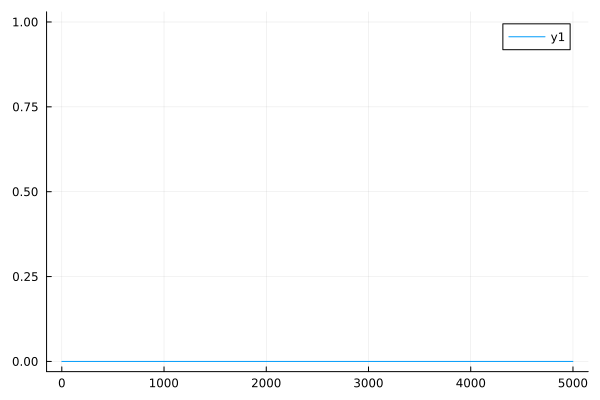

In [8]:
Plots.plot(y1 .- y2)

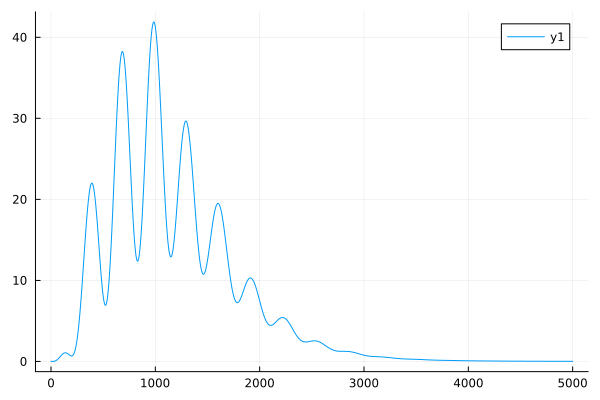

In [9]:
Plots.plot(Capse.get_Cℓ([3, 0.96, 67, 0.02, 0.12, 0.05], CℓEE_emu))

## PlanckLite and Turing

Here we are going to create some functions to analyze Planck data. The first function, given a list of arguments, retrieves the binned 
C<sub>l</sub>'s

In [10]:
lsTT = 2:2508
lsTE = 2:1996
facTT=lsTT.*(lsTT.+1)./(2*π)
facTE=lsTE.*(lsTE.+1)./(2*π)

function call_emu_planck(θ, Emu_TT, Emu_TE, Emu_EE, facTT, facTE)
    return PlanckLite.bin_Cℓ(Capse.get_Cℓ(θ, Emu_TT)[1:2507]./facTT,
                            Capse.get_Cℓ(θ, Emu_TE)[1:1995]./facTE,
                            Capse.get_Cℓ(θ, Emu_EE)[1:1995]./facTE)
end

call_emu_planck (generic function with 1 method)

This other function is a closure, defining a more manageable version of the same function (in this way we don't have to pass some fixed arguments)

In [11]:
theory_planck(θ) = call_emu_planck(θ, CℓTT_emu, CℓTE_emu, CℓEE_emu, facTT, facTE)

theory_planck (generic function with 1 method)

Let us now define a dummy scalar function (i.e. a function $R^n$ -> $R^1$), that we are gonna use as a benchmark to evaluate gradients

In [12]:
x = [3.044, 0.96, 67., 0.02, 0.12, 0.06]
@benchmark theory_planck($x)

BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  171.625 μs …  26.199 ms  ┊ GC (min … max):  0.00% … 98.94%
 Time  (median):     198.833 μs               ┊ GC (median):     0.00%
 Time  (mean ± σ):   240.757 μs ± 422.606 μs  ┊ GC (mean ± σ):  16.52% ± 14.81%

  ▇█▆▅▃▁                                                        ▂
  ███████▆▆▅▄▁▃▄▃▁▁▃▃▁▃▁▃▃▄▁▃▁▁▁▁▁▁▁▁▃▃▁▁▁▅▆▇▇▆▆▅▆▆▇█▇▇▇▆▆▆▆▅▄▅ █
  172 μs        Histogram: log(frequency) by time       1.14 ms <

 Memory estimate: 895.61 KiB, allocs estimate: 186.

In [13]:
mytest(x) = sum(abs2, theory_planck(x))

mytest (generic function with 1 method)

In [14]:
@benchmark (mytest($x))

BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  171.667 μs …  21.895 ms  ┊ GC (min … max):  0.00% … 98.80%
 Time  (median):     200.167 μs               ┊ GC (median):     0.00%
 Time  (mean ± σ):   243.781 μs ± 374.135 μs  ┊ GC (mean ± σ):  17.02% ± 14.89%

  ▆█▆▄▂                                                         ▁
  ██████▆▄▁▃▃▁▃▁▁▁▁▃▃▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▆▆▆▅▆▇▇▇▇▇▇▇▆▆▆▅▃▄▁▄▃▃▄▁▄ █
  172 μs        Histogram: log(frequency) by time       1.31 ms <

 Memory estimate: 895.62 KiB, allocs estimate: 187.

We are now ready to perform autodiff! Here we are gonna use two different AD backends:
- ForwardDiff.jl, that performs Forward AD, which scales as the number of input parameters (with some caveats)
- Zygote.jl, that performs Backward AD, which scales as the number of output parameters

In [15]:
@benchmark ForwardDiff.gradient(mytest, $x)

BenchmarkTools.Trial: 3449 samples with 1 evaluation per sample.
 Range (min … max):  1.021 ms …  10.667 ms  ┊ GC (min … max):  0.00% … 89.00%
 Time  (median):     1.274 ms               ┊ GC (median):     0.00%
 Time  (mean ± σ):   1.449 ms ± 502.866 μs  ┊ GC (mean ± σ):  13.79% ± 17.87%

        █▇▁ ▂                                                  
  ▅▃▃▃▆████▇█▇▅▃▃▂▂▂▂▂▁▂▁▂▂▂▂▂▃▃▃▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂ ▃
  1.02 ms         Histogram: frequency by time        2.84 ms <

 Memory estimate: 4.39 MiB, allocs estimate: 243.

In this specific example, the difference is not that big, since we are differentiating wrt only 6 parameters (but things get quickly better for Zygote.jl as the dimensionality of the problem increses).

We are now ready to instantiate our problem using Turing.jl!

# Creating a likelihood with a Probabilistic Programming Language

In this part of the notebook we are gonna show how to use Turing.jl, the state-of-the-art Probabilistic Programming Language (PPL) in the Julia ecosystem.

Before starting, we can take advantage of a bit of math to improve the performance of our inference.

Since the Covariance matrix we are gonna use does not depend on the model parameters, we can reparametrize our problem; let us define the following quantities

$\Gamma$ = sqrt($\Lambda$)

i $\Gamma$ = inv($\Gamma$)

D = i $\Gamma$ * d

We can now sample a MvNormal with an easier covariance matrix

D ~ MvNormal(i $\Gamma$ * t($\theta$), I)

The advantage of this reparametrization is that we compute the inverse of a matrix just once and not at every step of the MCMC, without resoirting to any approximation: the two likelihood defined are mathematically equivalent.

The covariance matrix and the data are supplied by the PlanckLite.jl package.

In [16]:
Γ = sqrt(PlanckLite.cov)
iΓ = inv(Γ)
D = iΓ * PlanckLite.data;

Although this is a bit different from the way we are used to code likelihoods in cosmology, it is easy to explain how to use a PPL such as Turing.jl.

When we use the "~" symbol, we are saying that the left-hand-side is sampled from the distribution on the right-hand-side

In [17]:
@model function CMB_planck(iΓ)
    #prior on model parameters
    ln10As ~ Uniform(0.25, 0.35)
    ns     ~ Uniform(0.88, 1.06)
    h      ~ Uniform(0.60, 0.80)
    ωb     ~ Uniform(0.1985, 0.25)
    ωc     ~ Uniform(0.08, 0.20)
    τ      ~ Normal(0.0506, 0.0086)
    yₚ     ~ Normal(1.0, 0.0025)

    θ = [10*ln10As, ns, 100*h, ωb/10, ωc, τ]

    #compute theoretical prediction
    pred := iΓ * theory_planck(θ) ./(yₚ^2)
    #compute likelihood
    D ~ MvNormal(pred, I)

    return nothing
end

CMB_model_planck = CMB_planck(iΓ);

Since D is supplied to our model as an input, Turing.jl understand it to be a part of the likelihood, rather than a parameter drawn from the prior.

Let us perform the MAP computation. Turing.jl has been interfaced with Optim.jl, which provides some powerful minimization methods such as L-BFGS.

In [18]:
bestfit_Planck = optimize(CMB_planck(iΓ) | (; D), MAP(), Optim.Options(iterations=100000, allow_f_increases=true))
@benchmark optimize(CMB_planck(iΓ) | (; D), MAP(), Optim.Options(iterations=100000, allow_f_increases=true))

BenchmarkTools.Trial: 18 samples with 1 evaluation per sample.
 Range (min … max):  184.277 ms … 406.009 ms  ┊ GC (min … max): 10.83% … 12.85%
 Time  (median):     281.921 ms               ┊ GC (median):    13.16%
 Time  (mean ± σ):   283.172 ms ±  68.688 ms  ┊ GC (mean ± σ):  13.45% ±  1.54%

  █    ▁    ▁▁ ▁▁        ▁ ▁  ▁  ▁   ▁▁     █    ▁           ▁▁  
  █▁▁▁▁█▁▁▁▁██▁██▁▁▁▁▁▁▁▁█▁█▁▁█▁▁█▁▁▁██▁▁▁▁▁█▁▁▁▁█▁▁▁▁▁▁▁▁▁▁▁██ ▁
  184 ms           Histogram: frequency by time          406 ms <

 Memory estimate: 506.93 MiB, allocs estimate: 51797.

The minimization takes less than half a second!

We are going to run a chain, with 250 adaptation steps and 1000 steps (note that Turing.jl will not retrieve the burn-in steps)

In [19]:
nsteps = 1000
nadapts = 250;

Before starting chains, let us use Pathfinder.jl, a Julia implementation of the Pathfinder algorithm. Pathfinder is an approximate method that quickly gives approximate samples from the posterior distribution. It can be used to replace a standard MCMC or initialize it. Here we are gonna use the parallel version, that performs multiples runs and merges them.

In [20]:
result_multi = multipathfinder(CMB_planck(iΓ) | (; D), 2000; nruns=4)

Multi-path Pathfinder result
  runs: 4
  draws: 2000
  Pareto shape diagnostic: 0.15 (good)

In [21]:
describe(result_multi.draws_transformed)

Chains MCMC chain (2000×620×1 Array{Float64, 3}):

Iterations        = 1:1:2000
Number of chains  = 1
Samples per chain = 2000
parameters        = ln10As, ns, h, ωb, ωc, τ, yₚ, pred[1], pred[2], pred[3], pred[4], pred[5], pred[6], pred[7], pred[8], pred[9], pred[10], pred[11], pred[12], pred[13], pred[14], pred[15], pred[16], pred[17], pred[18], pred[19], pred[20], pred[21], pred[22], pred[23], pred[24], pred[25], pred[26], pred[27], pred[28], pred[29], pred[30], pred[31], pred[32], pred[33], pred[34], pred[35], pred[36], pred[37], pred[38], pred[39], pred[40], pred[41], pred[42], pred[43], pred[44], pred[45], pred[46], pred[47], pred[48], pred[49], pred[50], pred[51], pred[52], pred[53], pred[54], pred[55], pred[56], pred[57], pred[58], pred[59], pred[60], pred[61], pred[62], pred[63], pred[64], pred[65], pred[66], pred[67], pred[68], pred[69], pred[70], pred[71], pred[72], pred[73], pred[74], pred[75], pred[76], pred[77], pred[78], pred[79], pred[80], pred[81], pred[82], pred[83], pr

In [22]:
@time multipathfinder(CMB_planck(iΓ) | (; D), 2000; nruns=4)

  5.962657 seconds (9.30 M allocations: 21.702 GiB, 21.96% gc time, 0.00% compilation time)


Multi-path Pathfinder result
  runs: 4
  draws: 2000
  Pareto shape diagnostic: 0.62 (ok)

Pathfinder is incredibly fast: it performed the analysis on my laptop in as few as 5 seconds. However, it is an approximate method. Although it might not always used to give a faithful approximation of the posterior, it is very useful in starting the chains close to the typical set.

Here we are gonna use some Pathfinder draws to initialize our chains (here the snippet of code is written as if we had to run 4 chains, so we took 4 samples from Pathfinder's draws).

In [23]:
init_params = collect.(eachrow(result_multi.draws_transformed.value[1:4, :, 1]))

4-element Vector{Vector{Float64}}:
 [0.3069088448028244, 0.9589879824553985, 0.6650613919052628, 0.2239125713344209, 0.12216770478573168, 0.0628017989224567, 1.0019553412509012, 9.710256443247005, 10.868870852955938, 11.610276769181365  …  -0.9446488308454271, 1.9179307042210387, 1.454246852402924, 0.937043598881372, 0.07383351966244937, 0.9303630697607531, 0.6717772893563674, 0.8237827465640699, 0.5047731389269539, 0.810347061778064]
 [0.30554868365797977, 0.9613137268331418, 0.668078397024992, 0.22400379748193025, 0.12137837976170461, 0.05530730730995511, 1.0025916668543153, 9.651548220433833, 10.811525071755417, 11.557301023006891  …  -0.9470296875114721, 1.9232290613182157, 1.459405604008445, 0.9403804621482732, 0.0760209249768807, 0.932850382672618, 0.6751360954617868, 0.8279034881479155, 0.5066641576000026, 0.8124627960535121]
 [0.3071842152466881, 0.9624132917305165, 0.6719289765587044, 0.22237482603403347, 0.12000405039256468, 0.06551843953752043, 1.0034260959741117, 9.62393273

We are now ready to start the No-U-Turn-Sampler (NUTS) chains! We need to set:

- the number of burn-in and accepted steps
- the target acceptance-ratio (here we ar gonna use the standard 0.75)
- the initial point for our chains
- the AD backend (we are using both ForwardDiff.jl and Zygote.jl)

In [24]:
chains_planck_nuts_fd = sample(CMB_planck(iΓ) | (; D), NUTS(nadapts, 0.75, adtype=AutoForwardDiff()), nsteps; init_params = init_params[1])

Sampling   0%|                                          |  ETA: N/A
┌ Info: Found initial step size
│   ϵ = 0.00078125
└ @ Turing.Inference /Users/ethansmith/.julia/packages/Turing/gtb9I/src/mcmc/hmc.jl:216
Sampling   1%|▎                                         |  ETA: 0:08:43
Sampling   1%|▍                                         |  ETA: 0:04:58
Sampling   2%|▋                                         |  ETA: 0:04:16
Sampling   2%|▉                                         |  ETA: 0:05:50
Sampling   3%|█▏                                        |  ETA: 0:07:50
Sampling   3%|█▎                                        |  ETA: 0:08:31
Sampling   4%|█▌                                        |  ETA: 0:09:06
Sampling   4%|█▋                                        |  ETA: 0:10:03
Sampling   5%|█▉                                        |  ETA: 0:09:19
Sampling   5%|██▏                                       |  ETA: 0:10:12
Sampling   6%|██▍                                       |  ETA: 0:10:50
S

Chains MCMC chain (1000×634×1 Array{Float64, 3}):

Iterations        = 251:1:1250
Number of chains  = 1
Samples per chain = 1000
Wall duration     = 190.32 seconds
Compute duration  = 190.32 seconds
parameters        = ln10As, ns, h, ωb, ωc, τ, yₚ, pred[1], pred[2], pred[3], pred[4], pred[5], pred[6], pred[7], pred[8], pred[9], pred[10], pred[11], pred[12], pred[13], pred[14], pred[15], pred[16], pred[17], pred[18], pred[19], pred[20], pred[21], pred[22], pred[23], pred[24], pred[25], pred[26], pred[27], pred[28], pred[29], pred[30], pred[31], pred[32], pred[33], pred[34], pred[35], pred[36], pred[37], pred[38], pred[39], pred[40], pred[41], pred[42], pred[43], pred[44], pred[45], pred[46], pred[47], pred[48], pred[49], pred[50], pred[51], pred[52], pred[53], pred[54], pred[55], pred[56], pred[57], pred[58], pred[59], pred[60], pred[61], pred[62], pred[63], pred[64], pred[65], pred[66], pred[67], pred[68], pred[69], pred[70], pred[71], pred[72], pred[73], pred[74], pred[75], pred[76], 

In [25]:
describe(chains_planck_nuts_fd)

Chains MCMC chain (1000×634×1 Array{Float64, 3}):

Iterations        = 251:1:1250
Number of chains  = 1
Samples per chain = 1000
Wall duration     = 190.32 seconds
Compute duration  = 190.32 seconds
parameters        = ln10As, ns, h, ωb, ωc, τ, yₚ, pred[1], pred[2], pred[3], pred[4], pred[5], pred[6], pred[7], pred[8], pred[9], pred[10], pred[11], pred[12], pred[13], pred[14], pred[15], pred[16], pred[17], pred[18], pred[19], pred[20], pred[21], pred[22], pred[23], pred[24], pred[25], pred[26], pred[27], pred[28], pred[29], pred[30], pred[31], pred[32], pred[33], pred[34], pred[35], pred[36], pred[37], pred[38], pred[39], pred[40], pred[41], pred[42], pred[43], pred[44], pred[45], pred[46], pred[47], pred[48], pred[49], pred[50], pred[51], pred[52], pred[53], pred[54], pred[55], pred[56], pred[57], pred[58], pred[59], pred[60], pred[61], pred[62], pred[63], pred[64], pred[65], pred[66], pred[67], pred[68], pred[69], pred[70], pred[71], pred[72], pred[73], pred[74], pred[75], pred[76], 

An interesting quantity we will compare with the MCHMC runs is the ESS per second

In [26]:
@info compute_ESS_s(chains_planck_nuts_fd)

┌ Info: 2.3810847342152837
└ @ Main /Users/ethansmith/Desktop/Waterloo/Masters/JulaiLocalEnv/capse_planck_manual_LOOPIT.ipynb:1


An ESS/s of 1.6 means that we can reach the (heuristic) threshold of 400 ESS in around 4 minutes and, taking advantage of the multiple processor, our analysis can be performed in around 1 minute.

# Using Inference Data

In [27]:
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants

In [28]:
chains_planck_nuts_fd

Chains MCMC chain (1000×634×1 Array{Float64, 3}):

Iterations        = 251:1:1250
Number of chains  = 1
Samples per chain = 1000
Wall duration     = 190.32 seconds
Compute duration  = 190.32 seconds
parameters        = ln10As, ns, h, ωb, ωc, τ, yₚ, pred[1], pred[2], pred[3], pred[4], pred[5], pred[6], pred[7], pred[8], pred[9], pred[10], pred[11], pred[12], pred[13], pred[14], pred[15], pred[16], pred[17], pred[18], pred[19], pred[20], pred[21], pred[22], pred[23], pred[24], pred[25], pred[26], pred[27], pred[28], pred[29], pred[30], pred[31], pred[32], pred[33], pred[34], pred[35], pred[36], pred[37], pred[38], pred[39], pred[40], pred[41], pred[42], pred[43], pred[44], pred[45], pred[46], pred[47], pred[48], pred[49], pred[50], pred[51], pred[52], pred[53], pred[54], pred[55], pred[56], pred[57], pred[58], pred[59], pred[60], pred[61], pred[62], pred[63], pred[64], pred[65], pred[66], pred[67], pred[68], pred[69], pred[70], pred[71], pred[72], pred[73], pred[74], pred[75], pred[76], 

In [29]:
y_pred = predict(CMB_planck(iΓ), chains_planck_nuts_fd)
describe(y_pred)

Chains MCMC chain (1000×613×1 Array{Float64, 3}):

Iterations        = 1:1:1000
Number of chains  = 1
Samples per chain = 1000
parameters        = D[1], D[2], D[3], D[4], D[5], D[6], D[7], D[8], D[9], D[10], D[11], D[12], D[13], D[14], D[15], D[16], D[17], D[18], D[19], D[20], D[21], D[22], D[23], D[24], D[25], D[26], D[27], D[28], D[29], D[30], D[31], D[32], D[33], D[34], D[35], D[36], D[37], D[38], D[39], D[40], D[41], D[42], D[43], D[44], D[45], D[46], D[47], D[48], D[49], D[50], D[51], D[52], D[53], D[54], D[55], D[56], D[57], D[58], D[59], D[60], D[61], D[62], D[63], D[64], D[65], D[66], D[67], D[68], D[69], D[70], D[71], D[72], D[73], D[74], D[75], D[76], D[77], D[78], D[79], D[80], D[81], D[82], D[83], D[84], D[85], D[86], D[87], D[88], D[89], D[90], D[91], D[92], D[93], D[94], D[95], D[96], D[97], D[98], D[99], D[100], D[101], D[102], D[103], D[104], D[105], D[106], D[107], D[108], D[109], D[110], D[111], D[112], D[113], D[114], D[115], D[116], D[117], D[118], D[119], D[120], D

In [30]:
idata = from_mcmcchains(
        chains_planck_nuts_fd;
        posterior_predictive = y_pred,
        constant_data=(; x),
        observed_data=(; D),
        dims=(x=[:i], D=[:i], pred=[:i]),
)

InferenceData with groups:
  > posterior
  > posterior_predictive
  > sample_stats
  > observed_data
  > constant_data

In [31]:
function inv_diag_cholesky(F::Cholesky)
    if F.uplo == 'U'
        U = inv(UpperTriangular(F.factors))
        return map(Base.Fix1(sum, abs2), eachrow(U))
    else
        L = inv(LowerTriangular(F.factors))
        return map(Base.Fix1(sum, abs2), eachcol(L))
    end
end

function pointwise_normal_loglikelihood!(
    log_like::AbstractArray,
    cov::AbstractMatrix,
    mean::AbstractVector,
    obs::AbstractVector,
)
    F = cholesky(cov)
    c = inv_diag_cholesky(F)
    g = F \ (obs - mean)
    @. log_like = (log(c) - g^2 / c - log2π) ./ 2
end

function pointwise_normal_loglikelihood(
    obs::AbstractVector, mean::AbstractArray, cov::AbstractArray
)
    num_sample_dims = ndims(mean) - 1
    @assert num_sample_dims ∈ (1, 2)
    @assert ndims(cov) == num_sample_dims + 2
    @assert length(obs) ==
        size(mean, num_sample_dims + 1) ==
        size(cov, num_sample_dims + 1) ==
        size(cov, num_sample_dims + 2)

    cov_dims = ntuple(i -> i + num_sample_dims, 2)
    sample_dims = ntuple(identity, num_sample_dims)

    cov_axes = map(i -> axes(cov, i), cov_dims)
    sample_axes = map(i -> axes(cov, i), sample_dims)
    out_axes = (sample_axes..., cov_axes[1])

    log_like = similar(obs, Base.promote_eltype(obs, mean, cov), out_axes)
    foreach(
        pointwise_normal_loglikelihood!,
        eachslice(log_like; dims=sample_dims),
        eachslice(cov; dims=sample_dims),
        eachslice(mean; dims=sample_dims),
        Iterators.repeated(obs),
    )

    return log_like
end


pointwise_normal_loglikelihood (generic function with 1 method)

In [32]:
I613 = Matrix{Float64}(I, 613, 613)
Id = repeat(reshape(I613, 1, 1, 613, 613), nsteps, 1, 1, 1)

1000×1×613×613 Array{Float64, 4}:
[:, :, 1, 1] =
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 ⋮
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0

[:, :, 2, 1] =
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

[:, :, 3, 1] =
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

;;; … 

[:, :, 611, 1] =
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

[:, :, 612, 1] =
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

[:, :, 613, 1] =
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

[:, :, 1, 2] =
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

[:, :, 2, 2] =
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 ⋮
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0

[:, :, 3, 2] =
 0.0
 0.0
 0.0
 0.0
 0.0


In [33]:
log_like = pointwise_normal_loglikelihood(
    idata.observed_data.D,
    idata.posterior.pred,
    Id,
)

1000×1×613 Array{Float64, 3}:
[:, :, 1] =
 -0.9205252851578148
 -0.9193247468094801
 -0.9189388461644522
 -0.9192568746857424
 -0.919350765928222
 -0.9189442786107479
 -0.9198433312753332
 -0.9204739831916692
 -0.9219204624523434
 -0.9210067722201536
  ⋮
 -0.9206036208043132
 -0.9201561421162385
 -0.9233761154532784
 -0.919390189769988
 -0.9423530461578347
 -0.9190068295002393
 -0.9189644414902189
 -0.9203286748789489
 -0.9294723430472205

[:, :, 2] =
 -0.9202540991398944
 -0.9191986024924486
 -0.9189390792822546
 -0.9192586218093655
 -0.9193113358359776
 -0.918968731771631
 -0.9196673152219512
 -0.9203421192069379
 -0.9223677558118385
 -0.9209495399784399
  ⋮
 -0.9212253055482714
 -0.9198272926796203
 -0.9247188582744759
 -0.9193109163995116
 -0.9442647655878754
 -0.9190216974794582
 -0.9189747240571604
 -0.9204320436117815
 -0.9305269946798296

[:, :, 3] =
 -1.803132546967376
 -1.7674312684205782
 -1.7431619820079585
 -1.7162594795161765
 -1.7162480063000265
 -1.7633037014758493
 -1.

In [34]:
idata = merge(
        idata,
        InferenceData(; log_likelihood=namedtuple_to_dataset((; D=log_like))),
)

InferenceData with groups:
  > posterior
  > posterior_predictive
  > log_likelihood
  > sample_stats
  > observed_data
  > constant_data

In [35]:
idata.log_likelihood

┌ 1000×1×613 Dataset ┐
├────────────────────┴────────────────────────────────────── dims ┐
  ↓ draw, → chain, ↗ D_dim_1
├───────────────────────────────────────────────────────── layers ┤
  :D eltype: Float64 dims: draw, chain, D_dim_1 size: 1000×1×613
├─────────────────────────────────────────────────────── metadata ┤
  Dict{String, Any} with 1 entry:
  "created_at" => "2026-03-05T12:33:26.547"


In [36]:
idata.log_likelihood[:D]

┌ 1000×1×613 DimArray{Float64, 3} D ┐
├───────────────────────────── dims ┤
  ↓ draw, → chain, ↗ D_dim_1
└───────────────────────────────────┘
[:, :, 1]
 -0.920525
 -0.919325
 -0.918939
 -0.919257
 -0.919351
 -0.918944
 -0.919843
  ⋮
 -0.923376
 -0.91939
 -0.942353
 -0.919007
 -0.918964
 -0.920329
 -0.929472

### Instead of performing LOO-PIT using the defined function, this notebook completes the steps of LOO-PIT analysis "manually" in order to provide greater visibility of the process. 

In [37]:
#loo_pit_y = loo_pit(idata; y_name=:D)
# This is the defined function call that could be used alternatively

The following cells are simply to show the structure of idata.log_likelihood, which is a 1000x1x613 array representing 1000 draws of a single chain of the 613 bins (which can be thought of as "voxels").

We pull the structure back layer by layer for clarity.

In [38]:
idata.log_likelihood

┌ 1000×1×613 Dataset ┐
├────────────────────┴────────────────────────────────────── dims ┐
  ↓ draw, → chain, ↗ D_dim_1
├───────────────────────────────────────────────────────── layers ┤
  :D eltype: Float64 dims: draw, chain, D_dim_1 size: 1000×1×613
├─────────────────────────────────────────────────────── metadata ┤
  Dict{String, Any} with 1 entry:
  "created_at" => "2026-03-05T12:33:26.547"


In [39]:
idata.log_likelihood[:,1,13]

┌ 1000-element Dataset ┐
├──────────────────────┴────────────── dims ┐
  ↓ draw
├─────────────────────────────────── layers ┤
  :D eltype: Float64 dims: draw size: 1000
├───────────────────────────────────────────┴ metadata ┐
  Dict{String, Any} with 1 entry:
  "created_at" => "2026-03-05T12:33:26.547"


In [40]:
idata.log_likelihood[:,1,13][:D]

┌ 1000-element DimArray{Float64, 1} D ┐
├─────────────────────────────── dims ┤
  ↓ draw
└─────────────────────────────────────┘
 -0.943265
 -0.946169
 -0.937824
 -0.935773
 -0.932076
 -0.924393
 -0.926402
  ⋮
 -0.920564
 -0.939433
 -0.919245
 -0.937552
 -0.931134
 -0.94326
 -0.919128

In [41]:
Array(idata.log_likelihood[:,1,13][:D])

1000-element Vector{Float64}:
 -0.9432646450864658
 -0.9461694794202884
 -0.9378239057848691
 -0.9357734882427305
 -0.9320756176171632
 -0.9243934408028758
 -0.9264018426823755
 -0.9315243488144958
 -0.9210938337213606
 -0.932043863724343
  ⋮
 -0.9190403015079398
 -0.923205760590694
 -0.9205639774575262
 -0.9394334019839994
 -0.9192449171611786
 -0.9375520886994403
 -0.931133963788243
 -0.9432596199388764
 -0.9191275550709134

We now perform Pareto Smoothed Importance Sampling on each "Voxel" by taking the vector of 1000 data entries and passing it to the psis function. 

In [42]:
psis_result = Vector{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 613);

In [43]:
for i in 1:613
    psis_result[i] = psis(Array(idata.log_likelihood[:,1,i][:D]))
end

In [72]:
psis_result[1].weights

1000-element Vector{Float64}:
 0.0010043020975614213
 0.0010055085247790251
 0.001005896928862399
 0.0010055767730940916
 0.0010054823626736826
 0.001005896928862399
 0.0010049872188600507
 0.001004353621555261
 0.001002901895070545
 0.0010038186554896572
 ⋮
 0.0010042234279886853
 0.0010046728971272064
 0.0010014430799392474
 0.0010054427234774876
 0.0009826179505396024
 0.001005828292722265
 0.0010058731565061338
 0.0010044995730891123
 0.0009953566260553488

The next step is to use the Pareto smoothed importance ratios and the previously calculated chain to perform Leave One Out (LOO) Cross Validation. 

This gives the posterior predictive distribution.

In [45]:
idata

InferenceData with groups:
  > posterior
  > posterior_predictive
  > log_likelihood
  > sample_stats
  > observed_data
  > constant_data

In [46]:
idata.posterior[:pred]

┌ 1000×1×613 DimArray{Float64, 3} pred ┐
├──────────────────────────────── dims ┤
  ↓ draw, → chain, ↗ i
└──────────────────────────────────────┘
[:, :, 1]
 9.58668
 9.61522
 9.64222
 9.66825
 9.67173
 9.63962
 9.68555
 ⋮
 9.5488
 9.61296
 9.42661
 9.6547
 9.63581
 9.69574
 9.49787

Extract one "step" of the chain, which has 613 µ values for multivariate normal distributions, generated by the chain for the 613 bins in the power spectrum

In [47]:
vec(idata.posterior[:pred][1,:,:])

613-element Vector{Float64}:
  9.586678974541169
 10.75198320435071
 11.507213928396466
 12.179478406401342
 12.899007675828942
 13.501735473784898
 14.140430027064433
 14.744610514531361
 15.292769042154264
 15.876253079168299
  ⋮
  1.9326191345412673
  1.4692282025462544
  0.9487088911971284
  0.08638381920422836
  0.9387824337587893
  0.6796588484186463
  0.831947666866773
  0.5110947994788307
  0.8120406137408464

Create a multivariate distribution using all of the µ values.

In [48]:
d = MvNormal(vec(idata.posterior[:pred][1,:,:]), I)

IsoNormal(
dim: 613
μ: [9.586678974541169, 10.75198320435071, 11.507213928396466, 12.179478406401342, 12.899007675828942, 13.501735473784898, 14.140430027064433, 14.744610514531361, 15.292769042154264, 15.876253079168299  …  -0.9390582598699427, 1.9326191345412673, 1.4692282025462544, 0.9487088911971284, 0.08638381920422836, 0.9387824337587893, 0.6796588484186463, 0.831947666866773, 0.5110947994788307, 0.8120406137408464]
Σ: [1.0 0.0 … 0.0 0.0; 0.0 1.0 … 0.0 0.0; … ; 0.0 0.0 … 1.0 0.0; 0.0 0.0 … 0.0 1.0]
)


Randomly sample from the multivariate distribution to obtain a draw from the liklihood $L(y_i | \theta)$ ~ $MVN(µ^s_i, \Sigma_i)$

In [49]:
draw = rand(d)

613-element Vector{Float64}:
  9.977703095740354
 11.212239237016417
 11.283424276622434
 11.891781743874127
 12.84770824021706
 12.949738853754363
 12.953742612965263
 13.577747232727587
 14.039724755629706
 14.943792766785526
  ⋮
  3.07541612812751
  1.95293977795927
  1.2449633544993106
 -1.1574273981944585
  1.723520790752013
  1.5628798199114269
  0.9857918250277615
  0.03711778132743171
  1.7105130361660585

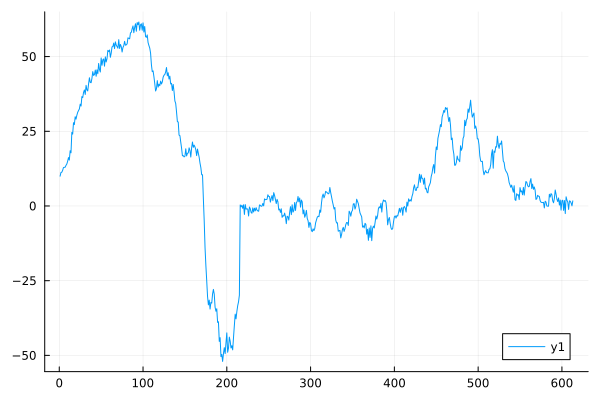

In [50]:
Plots.plot(draw)

Compare visually to the smooth stochastic realization that comes from the theory without noise

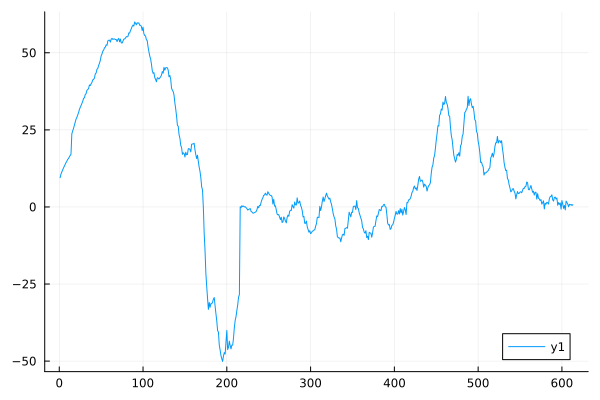

In [51]:
Plots.plot(iΓ * theory_planck(x))

We can plot the resulting sample relizations not just for a single step of the chain, but for every step of the chain.

Each chain step sets new values of $µ_i$, which sets a new multivariate normal distribution to draw a realization from.

In [52]:
draws = Vector{Vector{Float64}}(undef, 1000)

for i in 1:1000
    new_µ = vec(idata.posterior[:pred][i,:,:])
    dist = MvNormal(new_µ, I)
    draws[i] = rand(dist)
end
    

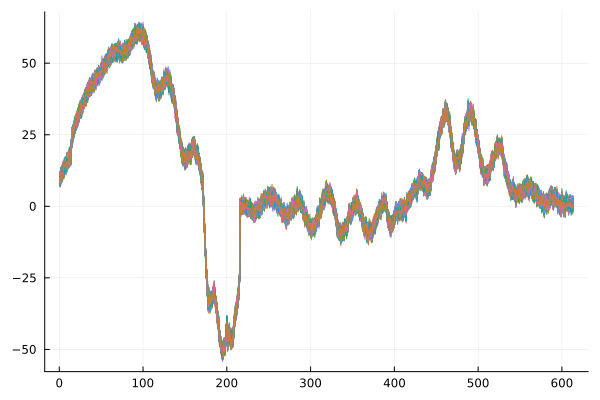

In [53]:
Plots.plot(draws, legend = false)

Visually it can be seen that the chain has converged quite well, as each chain step produces a similar realization of the model. 

Below is the plot of the data importated, showing strong visual similarities.

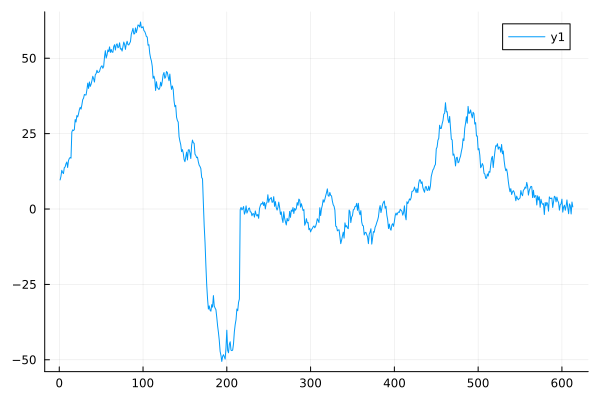

In [54]:
Plots.plot(D)

We can now compare pointwise (for each element in the 613 length array), the data to the produced realizations from the chain. 

PIT Comparison (Single Draw)

In [55]:
draw = draws[1];
data = D;
comparison_values = Vector{Float64}(undef, 613)

for i in 1:613
    if draw[i] > data[i]
        comparison_values[i] = 1
    else
        comparison_values[i] = 0
    end
end

In [56]:
comparison_values

613-element Vector{Float64}:
 1.0
 1.0
 0.0
 1.0
 1.0
 0.0
 1.0
 0.0
 0.0
 1.0
 ⋮
 1.0
 0.0
 1.0
 1.0
 0.0
 1.0
 1.0
 0.0
 0.0

In [57]:
pit_value = sum(comparison_values)/613

0.5203915171288744

PIT Comparison (All Draws)

In [83]:
PIT_Values = Vector{Float64}(undef, 1000)

for k in 1:1000
    draw =  draws[k]
    data = D
    comparison_values = Vector{Float64}(undef, 613)

    for i in 1:613
        if draw[i] > data[i]
            comparison_values[i] = 1
        else
            comparison_values[i] = 0
        end
    end
    
    pit_value = sum(comparison_values)/613
    
    PIT_Values[k] = pit_value
end

In [84]:
PIT_Values

1000-element Vector{Float64}:
 0.5203915171288744
 0.499184339314845
 0.49429037520391517
 0.46818923327895595
 0.48776508972267535
 0.46492659053833607
 0.47145187601957583
 0.4910277324632953
 0.4828711256117455
 0.4828711256117455
 ⋮
 0.49755301794453505
 0.45024469820554647
 0.5171288743882545
 0.49592169657422513
 0.4437194127243067
 0.5220228384991843
 0.4893964110929853
 0.4600326264274062
 0.4763458401305057

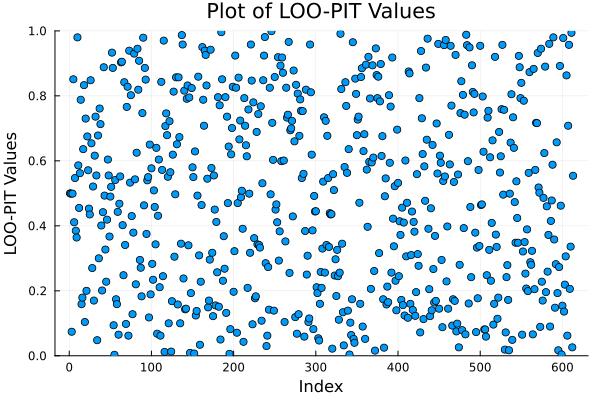

In [111]:
Plots.scatter(PIT_Values, ylims=(0,1), title="Plot of LOO-PIT Values", legend=false, xlabel="Index", ylabel="LOO-PIT Values")

In [94]:
comparison_values = Array{Float64}(undef, 613, 1000)

for j in 1:1000
    draw =  draws[j]
    data = D

    for i in 1:613
        if draw[i] > data[i]
            comparison_values[i, j] = 1
        else
            comparison_values[i, j] = 0
        end
    end
end

In [112]:
PIT_Values = Vector{Float64}(undef, 613)
for i in 1:613
    sum = 0
    for j in 1:1000
        sum += comparison_values[i,j] * psis_result[i].weights[j]
    end
    PIT_Values[i] = sum
end

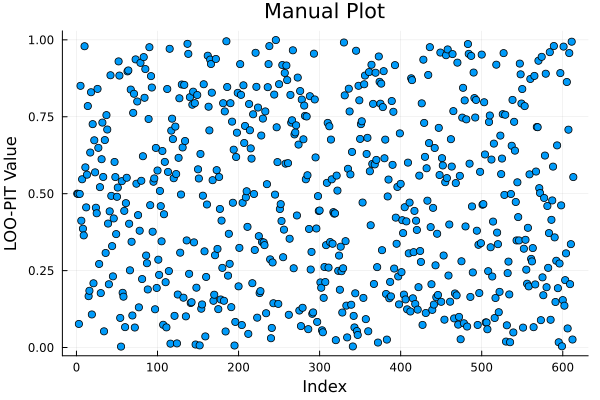

In [113]:
Plots.scatter(PIT_Values, legend=false, xlabel="Index", ylabel="LOO-PIT Value", title="Manual Plot")

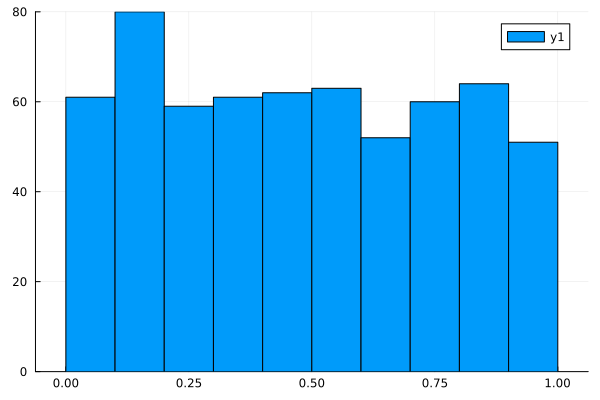

In [114]:
Plots.histogram(PIT_Values, bins=10)